## Random Forest Regression

We used Random Forest regression to predict average Attainment 8 scores using socioeconomic, demographic, geographical and school-related variables.

We chose Random Forest because it can account for nonlinear relationships and interactions between variables, which could be useful when investigating the different factors associated with GCSE attainment.

We used the training and test datasets prepared earlier in the project. Before fitting the model, we checked the structure of the data, missing values and the distribution of Attainment 8 scores.

### Use of AI

We used AI to help generate some of the code and troubleshoot errors. We checked the code and results throughout the analysis and made our own decisions about the modelling and how to interpret the results.

Training data: (7873, 78)
Test data: (1969, 78)

First five rows:


,school_urn,time_period,school_name,school_laestab,la_name,new_la_code,establishment_type_group,pcon_code,pcon_name,school_admission_type,...,ks4_first_language_other_than_english_attainment8_average,ks4_first_language_other_than_english_engmath_94_percent,ks4_first_language_other_than_english_engmath_95_percent,ks4_first_language_other_than_english_progress8_average,ks4_non_mobile_pupil_count,ks4_non_mobile_pupil_percent,ks4_non_mobile_attainment8_average,ks4_non_mobile_engmath_94_percent,ks4_non_mobile_engmath_95_percent,ks4_non_mobile_progress8_average
0,137773,202526,Kingswinford Academy,3325402,Dudley,E08000027,Converter academies,E14001316,Kingswinford and South Staffordshire,Non-selective schools in other areas,...,53.6,69.2,69.2,NaN,171.0,96.1,51.8,73.1,60.2,NaN
1,139234,202526,The JCB Academy,8606906,Staffordshire,E10000028,University technical college,E14001143,Burton and Uttoxeter,Non-selective schools in other areas,...,NaN,NaN,NaN,NaN,169.0,93.4,44.0,64.5,40.8,NaN
2,137218,202324,East Bergholt High School,9354097,Suffolk,E10000029,Converter academies,E14001494,South Suffolk,Non-selective schools in other areas,...,NaN,NaN,NaN,NaN,175.0,95.1,48.3,70.9,50.3,0.15
3,135479,202324,All Saints Catholic High School,3404615,Knowsley,E08000011,Voluntary aided school,E14001317,Knowsley,Non-selective schools in other areas,...,55.2,80.0,60.0,0.86,201.0,98.0,42.5,55.7,31.8,-0.36
4,116448,202425,The Wavell School,8504206,Hampshire,E10000014,Community school,E14001063,Aldershot,Non-selective schools in other areas,...,48.0,67.6,38.2,NaN,197.0,97.0,44.2,66.0,35.5,NaN



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 7873 entries, 0 to 7872
Data columns (total 78 columns):
 #   Column                                                     Non-Null Count  Dtype  
---  ------                                                     --------------  -----  
 0   school_urn                                                 7873 non-null   string 
 1   time_period                                                7873 non-null   string 
 2   school_name                                                7873 non-null   str    
 3   school_laestab                                             7873 non-null   int64  
 4   la_name                                                    7873 non-null   str    
 5   new_la_code                                                7873 non-null   str    
 6   establishment_type_group                                   7873 non-null   str    
 7   pcon_code                                                  7873 non-null   str    
 8 

,Train missing,Train missing (%),Test missing,Test missing (%)
ks4_first_language_other_than_english_progress8_average,5917,75.16,1496,75.98
ks4_boys_progress8_average,5418,68.82,1374,69.78
ks4_girls_progress8_average,5378,68.31,1364,69.27
ks4_disadvantaged_progress8_average,5280,67.06,1339,68.00
ks4_not_known_disadvantaged_progress8_average,5276,67.01,1338,67.95
...,...,...,...,...
ks4_disadvantaged_pupil_count,0,0.00,0,0.00
ks4_first_language_other_than_english_pupil_count,0,0.00,0,0.00
ks4_first_language_other_than_english_pupil_percent,0,0.00,0,0.00
ks4_non_mobile_pupil_percent,0,0.00,0,0.00



Total missing values in training: 52060
Rows with missing values: 7873


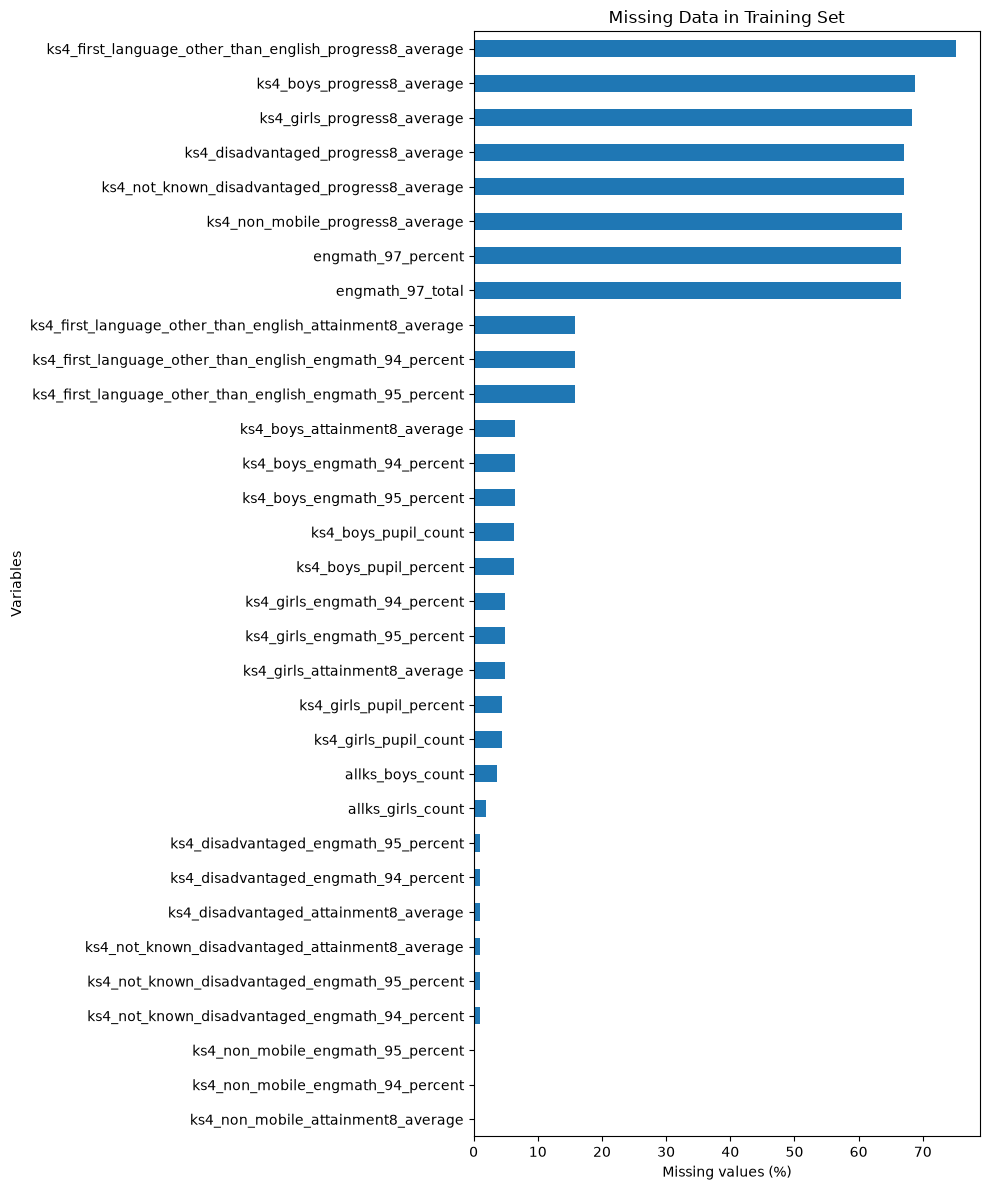


Missing data by year:


time_period,202324,202425,202526
school_urn,0.0,0.0,0.0
school_name,0.0,0.0,0.0
school_laestab,0.0,0.0,0.0
la_name,0.0,0.0,0.0
new_la_code,0.0,0.0,0.0
...,...,...,...
ks4_non_mobile_pupil_percent,0.0,0.0,0.0
ks4_non_mobile_attainment8_average,0.038081,0.382117,0.152091
ks4_non_mobile_engmath_94_percent,0.038081,0.382117,0.152091
ks4_non_mobile_engmath_95_percent,0.038081,0.382117,0.152091



Duplicate school-year records: 0
Unique schools: 3349

Records by academic year:


time_period
202324    2626
202425    2617
202526    2630
Name: count, dtype: int64[pyarrow]


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
school_laestab,7873.0,6730304.60,2719726.69,2024000.00,3524008.00,8404200.00,8884137.00,9436908.00
min_age,7873.0,10.72,1.66,0.00,11.00,11.00,11.00,14.00
max_age,7873.0,17.34,1.10,16.00,16.00,18.00,18.00,19.00
allks_pupil_count,7873.0,1086.92,394.92,0.00,818.00,1057.00,1331.00,3231.00
allks_boys_count,7580.0,568.30,247.03,0.00,410.00,550.00,711.00,1811.00
...,...,...,...,...,...,...,...,...
ks4_non_mobile_pupil_percent,7873.0,95.55,5.52,0.00,94.40,96.50,98.10,100.00
ks4_non_mobile_attainment8_average,7858.0,47.34,9.33,0.90,41.40,46.30,51.50,87.30
ks4_non_mobile_engmath_94_percent,7858.0,66.72,14.94,0.00,56.80,66.70,76.20,100.00
ks4_non_mobile_engmath_95_percent,7858.0,47.10,18.03,0.00,34.80,45.20,56.50,100.00



Attainment 8 summary:
count    7873.000000
mean       46.919345
std         9.421997
min         0.800000
25%        40.900000
50%        45.800000
75%        51.100000
max        87.300000
Name: attainment8_average, dtype: float64


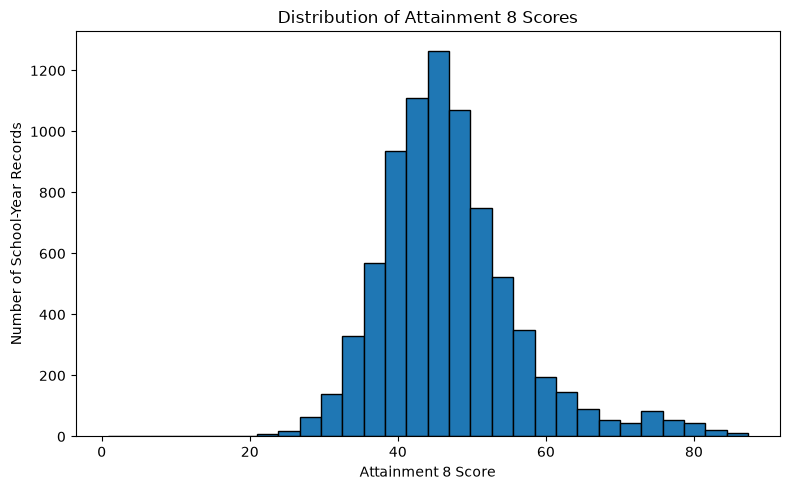

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load the training and test datasets
train_file = list(Path.cwd().rglob("attainment8_train.csv"))[0]
test_file = list(Path.cwd().rglob("attainment8_test.csv"))[0]

train = pd.read_csv(
    train_file,
    na_values=["z", "c", "x"],
    dtype={"school_urn": "string", "time_period": "string"}
)

test = pd.read_csv(
    test_file,
    na_values=["z", "c", "x"],
    dtype={"school_urn": "string", "time_period": "string"}
)

# Check the size and structure of the datasets
print("Training data:", train.shape)
print("Test data:", test.shape)

print("\nFirst five rows:")
display(train.head())

print("\nColumn information:")
train.info()


# Check missing values in both datasets
missing = pd.DataFrame({
    "Train missing": train.isna().sum(),
    "Train missing (%)": train.isna().mean() * 100,
    "Test missing": test.isna().sum(),
    "Test missing (%)": test.isna().mean() * 100
})

missing = missing.sort_values(
    "Train missing (%)", ascending=False
)

print("\nMissing values:")
display(missing.round(2))

print("\nTotal missing values in training:",
      train.isna().sum().sum())

print("Rows with missing values:",
      train.isna().any(axis=1).sum())


# Plot missing values in the training data
missing_percent = train.isna().mean() * 100
missing_percent = missing_percent[
    missing_percent > 0
].sort_values()

plt.figure(figsize=(10, 12))
missing_percent.plot(kind="barh")

plt.xlabel("Missing values (%)")
plt.ylabel("Variables")
plt.title("Missing Data in Training Set")

plt.tight_layout()
plt.show()


# Check missing data across academic years
missing_by_year = (
    train.groupby("time_period")
    .agg(lambda x: x.isna().mean() * 100)
    .T
)

print("\nMissing data by year:")
display(missing_by_year.round(2))


# Check duplicate school-year observations
print("\nDuplicate school-year records:",
      train.duplicated(
          subset=["school_urn", "time_period"]
      ).sum())

print("Unique schools:",
      train["school_urn"].nunique())

print("\nRecords by academic year:")
display(train["time_period"].value_counts().sort_index())


# Summary statistics for numerical variables
print("\nSummary statistics:")
display(train.describe().T.round(2))


# Examine the distribution of Attainment 8
print("\nAttainment 8 summary:")
print(train["attainment8_average"].describe())

plt.figure(figsize=(8, 5))

plt.hist(
    train["attainment8_average"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.xlabel("Attainment 8 Score")
plt.ylabel("Number of School-Year Records")
plt.title("Distribution of Attainment 8 Scores")

plt.tight_layout()
plt.show()

### Initial Data Exploration

The training dataset contained 7,873 observations and the test dataset contained 1,969, each with 78 variables. Each observation represented a school in a particular academic year.

We examined missing values and found that some variables, particularly Progress 8 measures, had large amounts of missing data. Some of these values were unavailable for entire academic years.

The variables we selected for the Random Forest had no missing values, and Attainment 8 was available for every observation in both datasets.

We also checked for duplicate school-year records and found none in the training data, which contained 3,349 different schools. We then examined the distribution of Attainment 8 scores before proceeding with the modelling.

### Selecting Predictors

We selected variables covering socioeconomic factors, pupil characteristics, geography and school information. These included disadvantage, SEN, first language, school size, admission type, local authority and parliamentary constituency.

We also included the average number of GCSE and qualification entries, as well as the percentage of pupils entering triple science or multiple languages. These describe the qualifications pupils enter rather than the grades they achieve.

We excluded previous attainment scores and other GCSE performance measures, as we wanted to investigate how well Attainment 8 could be predicted without directly using academic results.

Since some predictors were categorical and others were numerical, we needed to prepare them differently before fitting the model.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Select the predictors for the Random Forest
features = [
    "time_period",
    "la_name",
    "establishment_type_group",
    "pcon_name",
    "school_admission_type",
    "school_religious_character_detailed",
    "sex_policy",
    "min_age",
    "max_age",
    "allks_pupil_count",
    "endks4_pupil_count",
    "sen_pupil_count",
    "sen_pupil_percent",
    "sen_with_ehcp_pupil_count",
    "sen_with_ehcp_pupil_percent",
    "sen_no_ehcp_pupil_count",
    "sen_no_ehcp_pupil_percent",
    "pupil_count",
    "gcse_entries_average",
    "qual_entries_average",
    "sci_triple_entering_percent",
    "lan_multiple_entering_percent",
    "ks4_disadvantaged_pupil_count",
    "ks4_disadvantaged_pupil_percent",
    "ks4_not_known_disadvantaged_pupil_count",
    "ks4_not_known_disadvantaged_pupil_percent",
    "ks4_first_language_other_than_english_pupil_count",
    "ks4_first_language_other_than_english_pupil_percent",
    "ks4_non_mobile_pupil_count",
    "ks4_non_mobile_pupil_percent"
]

# Separate the predictors from the response variable
X_train = train[features].copy()
y_train = train["attainment8_average"]

# Treat academic year as a category rather than a number
X_train["time_period"] = X_train["time_period"].astype(str)

# Separate categorical and numerical predictors
categorical = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical = [
    col for col in features
    if col not in categorical
]

print("Total predictors:", len(features))
print("Categorical predictors:", len(categorical))
print("Numerical predictors:", len(numerical))

print("\nCategorical variables:")
print(categorical)

print("\nNumerical variables:")
print(numerical)


# Fill missing numerical values with the median
numerical_transformer = SimpleImputer(
    strategy="median"
)

# Fill missing categorical values and apply one-hot encoding
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing for numerical and categorical variables
preprocessor = ColumnTransformer([
    ("numerical", numerical_transformer, numerical),
    ("categorical", categorical_transformer, categorical)
])

print("\nPreprocessing pipeline created.")

Total predictors: 30
Categorical predictors: 7
Numerical predictors: 23

Categorical variables:
['time_period', 'la_name', 'establishment_type_group', 'pcon_name', 'school_admission_type', 'school_religious_character_detailed', 'sex_policy']

Numerical variables:
['min_age', 'max_age', 'allks_pupil_count', 'endks4_pupil_count', 'sen_pupil_count', 'sen_pupil_percent', 'sen_with_ehcp_pupil_count', 'sen_with_ehcp_pupil_percent', 'sen_no_ehcp_pupil_count', 'sen_no_ehcp_pupil_percent', 'pupil_count', 'gcse_entries_average', 'qual_entries_average', 'sci_triple_entering_percent', 'lan_multiple_entering_percent', 'ks4_disadvantaged_pupil_count', 'ks4_disadvantaged_pupil_percent', 'ks4_not_known_disadvantaged_pupil_count', 'ks4_not_known_disadvantaged_pupil_percent', 'ks4_first_language_other_than_english_pupil_count', 'ks4_first_language_other_than_english_pupil_percent', 'ks4_non_mobile_pupil_count', 'ks4_non_mobile_pupil_percent']

Preprocessing pipeline created.


### Data Preparation

We separated the predictors from the response variable, `attainment8_average`, and identified which variables were categorical or numerical.

Although our selected predictors had no missing values, we included median imputation for numerical variables and most-frequent imputation for categorical variables in case missing values needed to be handled.

We also used one-hot encoding for categorical variables, with `handle_unknown="ignore"` so the model could handle categories not present during training.

These preprocessing steps were included in a pipeline so that they would be fitted separately within each cross-validation fold, avoiding data leakage.

### Fitting the Random Forest

We fitted a Random Forest regression model using 100 decision trees. Each tree was fitted using a bootstrap sample of the training data. We set `max_features=0.5`, meaning half of the encoded features were considered at each split, and `min_samples_leaf=2` to help limit overfitting.

We used five-fold cross-validation to evaluate the model. This involved dividing the training data into five groups, training on four and validating on the remaining group. We repeated this for each fold and averaged the results.

We evaluated performance using MAE, RMSE and R². We also compared training and cross-validation performance to check for overfitting.

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Create the Random Forest model with preprocessing
rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_features=0.5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Use five-fold cross-validation on the training data
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate performance for each fold
scores = cross_validate(
    rf,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=1
)

# Show the results for all five folds
cv_results = pd.DataFrame({
    "MAE": -scores["test_MAE"],
    "RMSE": -scores["test_RMSE"],
    "R²": scores["test_R2"]
})

print("Cross-validation results:")
display(cv_results.round(3))

print("\nMean cross-validation results:")
display(cv_results.mean().round(3).to_frame("Mean").T)


# Fit the model on the full training set
rf.fit(X_train, y_train)

# Check performance on the training observations
train_predictions = rf.predict(X_train)

train_mae = mean_absolute_error(y_train, train_predictions)
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
train_r2 = r2_score(y_train, train_predictions)

# Compare training performance with cross-validation
performance_comparison = pd.DataFrame({
    "MAE": [train_mae, cv_results["MAE"].mean()],
    "RMSE": [train_rmse, cv_results["RMSE"].mean()],
    "R²": [train_r2, cv_results["R²"].mean()]
}, index=["Training", "Cross-validation"])

print("\nTraining vs cross-validation:")
display(performance_comparison.round(3))

Cross-validation results:


,MAE,RMSE,R²
0,3.132,4.117,0.817
1,3.074,3.943,0.831
2,3.092,3.928,0.818
3,3.122,3.947,0.830
4,3.189,4.105,0.795



Mean cross-validation results:


,MAE,RMSE,R²
Mean,3.122,4.008,0.818



Training vs cross-validation:


,MAE,RMSE,R²
Training,1.318,1.764,0.965
Cross-validation,3.122,4.008,0.818


### Model Performance

The Random Forest achieved a mean cross-validation MAE of 3.122, RMSE of 4.008 and R² of 0.818. The results were also fairly consistent across the five folds, with RMSE ranging from 3.928 to 4.117.

The training RMSE was considerably lower at 1.764, with an R² of 0.965. This suggests some overfitting, as the model performed much better on the training data than on the validation folds.

However, the cross-validation results still suggest that the model has reasonably strong predictive performance.

### Feature Importance

We examined feature importance to see which predictors the Random Forest relied on most.

We used impurity-based feature importance, which measures how much each variable contributes to reducing prediction error across the trees. Since categorical variables were one-hot encoded, we combined their importance scores to get one value for each original predictor.

One limitation of this method is that importance scores can be biased towards variables with many possible values. Correlated variables can also make the results harder to interpret. We therefore need to be careful about drawing conclusions from these scores [1].

Feature importance:


,Importance
gcse_entries_average,0.2479
school_admission_type,0.2366
qual_entries_average,0.0967
ks4_not_known_disadvantaged_pupil_percent,0.0739
ks4_disadvantaged_pupil_percent,0.0581
lan_multiple_entering_percent,0.0399
ks4_non_mobile_pupil_percent,0.0358
sci_triple_entering_percent,0.0209
allks_pupil_count,0.0170
ks4_first_language_other_than_english_pupil_percent,0.0155



Total importance: 1.0


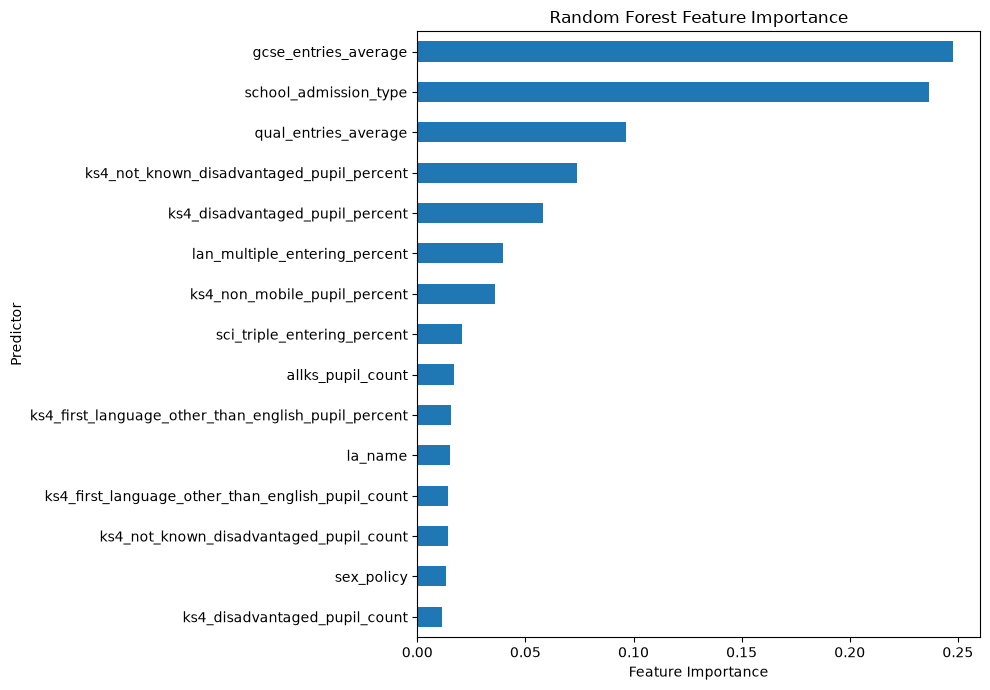

In [6]:
# Get importance scores from the fitted Random Forest
importances = rf.named_steps["model"].feature_importances_

# Match numerical predictors to their importance scores
grouped_importance = dict(
    zip(numerical, importances[:len(numerical)])
)

# Get the fitted one-hot encoder
encoder = (
    rf.named_steps["preprocessor"]
    .named_transformers_["categorical"]
    .named_steps["encoder"]
)

# Combine the importance of categories belonging to the same variable
position = len(numerical)

for column, categories in zip(categorical, encoder.categories_):
    n_categories = len(categories)

    grouped_importance[column] = importances[
        position:position + n_categories
    ].sum()

    position += n_categories

# Check that all encoded predictors have been included
assert position == len(importances)

# Sort predictors by importance
feature_importance = pd.Series(
    grouped_importance,
    name="Importance"
).sort_values(ascending=False)

print("Feature importance:")
display(feature_importance.to_frame().round(4))

print("\nTotal importance:", round(feature_importance.sum(), 4))

# Plot the 15 most important predictors
plt.figure(figsize=(10, 7))

feature_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Feature Importance")
plt.ylabel("Predictor")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

### Feature Importance Results

Average GCSE entries had the highest importance at 24.79%, followed by school admission type at 23.66% and average qualification entries at 9.67%.

The percentage of pupils with unknown disadvantage status and the percentage of disadvantaged pupils were also among the most important predictors, with importance scores of 7.39% and 5.81% respectively. This suggests that socioeconomic characteristics still contribute to the model's predictions, although the entry-related variables appear to have a greater influence.

The percentage entering multiple languages and triple science also contributed to the model, with importance scores of 3.99% and 2.09%. These variables may reflect differences in subject choices, school policies and pupil characteristics.

Geographical variables had relatively low importance scores, with local authority at 1.49% and parliamentary constituency at 1.06%. However, this does not necessarily mean that geography is unimportant, particularly as some of its information may overlap with other predictors.

These results should be interpreted carefully. Feature importance tells us which variables the model relied on, rather than showing which factors directly affect attainment. The scores can also be influenced by correlated predictors and variables with many categories [1].

It is also worth noting that Attainment 8 is calculated using results from up to eight qualifications [2]. This may help explain why GCSE and qualification entries were among the most important predictors. Although these variables do not measure grades directly, they are closely related to the outcome we are predicting.

### Geographical Predictors

We wanted to investigate whether including geographical information improved the Random Forest's performance. We compared the original model with another model that excluded local authority and parliamentary constituency.

We kept the other 28 predictors and the model settings the same, using five-fold cross-validation for both models.

This allowed us to see whether geographical information provided additional predictive value beyond the other school and pupil characteristics.

In [8]:
from sklearn.base import clone

# Remove local authority and parliamentary constituency
geographical_features = ["la_name", "pcon_name"]

no_geo_features = [
    col for col in features
    if col not in geographical_features
]

X_no_geo = X_train[no_geo_features].copy()

# Separate numerical and categorical predictors
categorical_no_geo = [
    col for col in categorical
    if col in no_geo_features
]

numerical_no_geo = [
    col for col in numerical
    if col in no_geo_features
]

# Set up preprocessing without geographical variables
no_geo_preprocessor = ColumnTransformer([
    ("numerical",
     SimpleImputer(strategy="median"),
     numerical_no_geo),

    ("categorical",
     Pipeline([
         ("imputer", SimpleImputer(strategy="most_frequent")),
         ("encoder", OneHotEncoder(handle_unknown="ignore"))
     ]),
     categorical_no_geo)
])

# Copy the original model with the updated preprocessing
no_geo_rf = clone(rf)
no_geo_rf.set_params(preprocessor=no_geo_preprocessor)

# Evaluate using the same five-fold cross-validation
no_geo_scores = cross_validate(
    no_geo_rf,
    X_no_geo,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=1
)

# Compare the two models
geo_comparison = pd.DataFrame({
    "Model": ["With geography", "Without geography"],
    "MAE": [
        -scores["test_MAE"].mean(),
        -no_geo_scores["test_MAE"].mean()
    ],
    "RMSE": [
        -scores["test_RMSE"].mean(),
        -no_geo_scores["test_RMSE"].mean()
    ],
    "R²": [
        scores["test_R2"].mean(),
        no_geo_scores["test_R2"].mean()
    ]
})

print("Cross-validation comparison:")
display(geo_comparison.round(3))

# Calculate the change in RMSE
rmse_with_geo = -scores["test_RMSE"].mean()
rmse_without_geo = -no_geo_scores["test_RMSE"].mean()

print(
    "\nChange in RMSE without geography:",
    round(rmse_without_geo - rmse_with_geo, 3)
)

Cross-validation comparison:


,Model,MAE,RMSE,R²
0,With geography,3.122,4.008,0.818
1,Without geography,3.180,4.073,0.812



Change in RMSE without geography: 0.065


### Geographical Comparison Results

Removing the geographical predictors increased the cross-validation RMSE from 4.008 to 4.073, while R² decreased from 0.818 to 0.812.

This suggests that geographical information provides some additional predictive value, although the improvement is relatively small. Some of the information contained in these variables may already be reflected in other predictors, such as disadvantage and school characteristics.

We decided to keep geography in the model because it slightly improved performance and was relevant to our investigation of factors associated with GCSE attainment.

### Cross-Validation by School

Our dataset contains observations from the same schools across different academic years. With ordinary K-Fold cross-validation, records from the same school can appear in both the training and validation sets.

We therefore also used GroupKFold, which keeps all observations from a particular school in the same fold. This allows us to evaluate how well the model predicts attainment for schools that were not included in its training folds [3].

We used five folds and kept the same Random Forest settings and all 30 predictors.

In [9]:
from sklearn.model_selection import GroupKFold

# Group observations by their unique school identifier
school_groups = train["school_urn"]

# Set up five-fold cross-validation grouped by school
group_cv = GroupKFold(n_splits=5)

# Evaluate the same Random Forest on unseen schools
group_scores = cross_validate(
    rf,
    X_train,
    y_train,
    groups=school_groups,
    cv=group_cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    n_jobs=1
)

# Compare ordinary K-Fold and GroupKFold
cv_comparison = pd.DataFrame({
    "Method": ["Ordinary K-Fold", "Grouped K-Fold"],
    "MAE": [
        -scores["test_MAE"].mean(),
        -group_scores["test_MAE"].mean()
    ],
    "RMSE": [
        -scores["test_RMSE"].mean(),
        -group_scores["test_RMSE"].mean()
    ],
    "R²": [
        scores["test_R2"].mean(),
        group_scores["test_R2"].mean()
    ]
})

print("Cross-validation comparison:")
display(cv_comparison.round(3))

# Check how much RMSE changes
rmse_difference = (
    -group_scores["test_RMSE"].mean()
    + scores["test_RMSE"].mean()
)

print(
    "\nIncrease in RMSE with GroupKFold:",
    round(rmse_difference, 3)
)

Cross-validation comparison:


,Method,MAE,RMSE,R²
0,Ordinary K-Fold,3.122,4.008,0.818
1,Grouped K-Fold,3.316,4.305,0.791



Increase in RMSE with GroupKFold: 0.297


### Cross-Validation Comparison Results

Ordinary K-Fold gave an RMSE of 4.008 and R² of 0.818, compared with an RMSE of 4.305 and R² of 0.791 for GroupKFold.

This suggests that the model performs better when observations from the same schools can appear in both training and validation. When schools are kept entirely separate, prediction errors increase.

However, the GroupKFold results still show reasonably strong predictive performance. The difference suggests that ordinary K-Fold may give a slightly optimistic estimate of how well the model would perform on completely unseen schools.

### Test Performance

We fitted the selected Random Forest on the full training set and evaluated it using the test data.

We calculated MAE, RMSE and R² to compare the test results with our cross-validation estimates. We also plotted the predicted scores against the actual scores and examined the residuals to see whether there were any patterns in the prediction errors.

Model performance:


,Method,MAE,RMSE,R²
0,Cross-validation,3.122,4.008,0.818
1,Test,3.031,3.879,0.810



Test observations: 1969


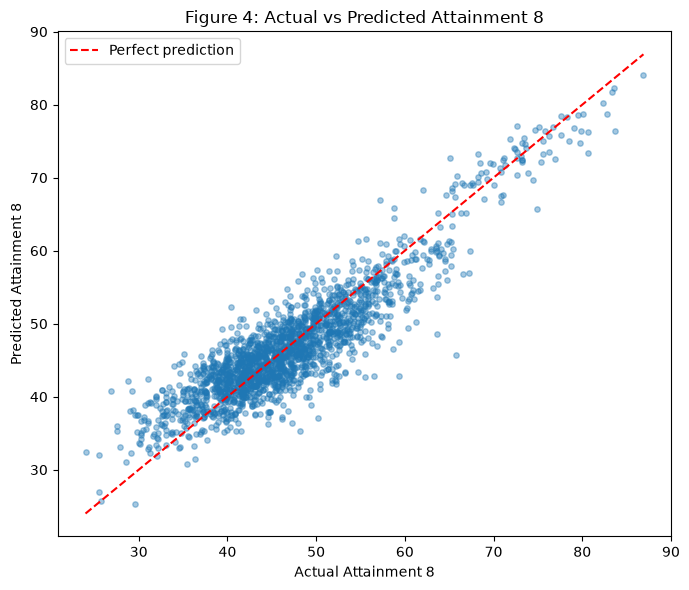

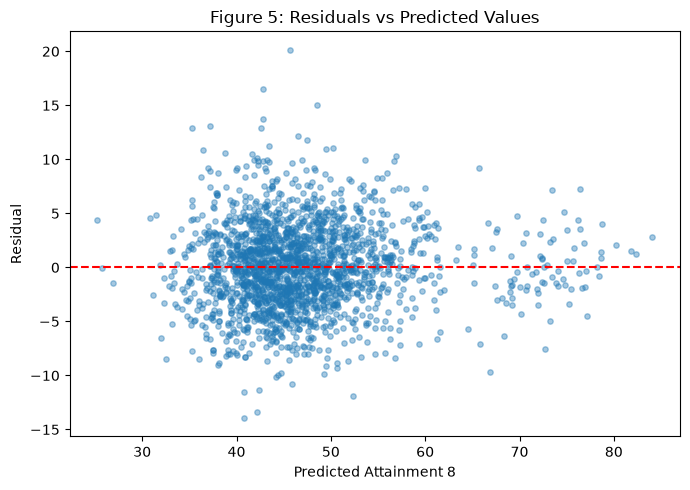

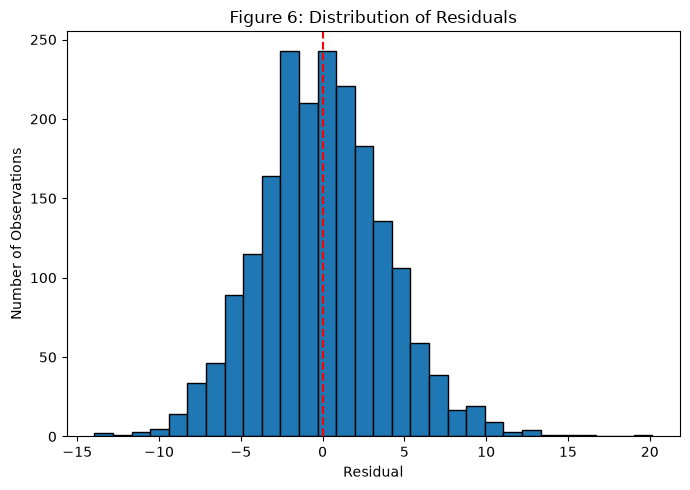

Mean residual: 0.026
Residual standard deviation: 3.879


In [10]:
# Prepare the test data using the same 30 predictors
X_test = test[features].copy()
X_test["time_period"] = X_test["time_period"].astype(str)

y_test = test["attainment8_average"]

# Fit the Random Forest on the full training set
rf.fit(X_train, y_train)

# Predict Attainment 8 scores for the test set
test_predictions = rf.predict(X_test)

# Calculate test performance
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

# Compare test results with cross-validation
test_comparison = pd.DataFrame({
    "Method": ["Cross-validation", "Test"],
    "MAE": [
        -scores["test_MAE"].mean(),
        test_mae
    ],
    "RMSE": [
        -scores["test_RMSE"].mean(),
        test_rmse
    ],
    "R²": [
        scores["test_R2"].mean(),
        test_r2
    ]
})

print("Model performance:")
display(test_comparison.round(3))

print("\nTest observations:", len(y_test))


# Figure 4: Actual vs predicted scores
plt.figure(figsize=(7, 6))

plt.scatter(y_test, test_predictions, alpha=0.4, s=15)

# Diagonal line represents perfect predictions
score_min = min(y_test.min(), test_predictions.min())
score_max = max(y_test.max(), test_predictions.max())

plt.plot(
    [score_min, score_max],
    [score_min, score_max],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Attainment 8")
plt.ylabel("Predicted Attainment 8")
plt.title("Figure 4: Actual vs Predicted Attainment 8")
plt.legend()
plt.tight_layout()
plt.show()


# Calculate residuals: actual minus predicted
residuals = y_test.to_numpy() - test_predictions

# Figure 5: Residuals against predicted scores
plt.figure(figsize=(7, 5))

plt.scatter(test_predictions, residuals, alpha=0.4, s=15)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Attainment 8")
plt.ylabel("Residual")
plt.title("Figure 5: Residuals vs Predicted Values")
plt.tight_layout()
plt.show()


# Figure 6: Distribution of residuals
plt.figure(figsize=(7, 5))

plt.hist(residuals, bins=30, edgecolor="black")
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residual")
plt.ylabel("Number of Observations")
plt.title("Figure 6: Distribution of Residuals")
plt.tight_layout()
plt.show()


# Check whether predictions are biased overall
print("Mean residual:", round(residuals.mean(), 3))
print("Residual standard deviation:", round(residuals.std(), 3))

### Test Results

The Random Forest achieved a test MAE of 3.031, RMSE of 3.879 and R² of 0.810. These results were close to the cross-validation estimates, suggesting that the model generalised reasonably well to the test data.

The actual versus predicted plot shows that most predictions were fairly close to the actual Attainment 8 scores. However, the model tended to overestimate lower scores and underestimate higher scores.

The residuals were roughly centred around zero, with a mean of 0.026, suggesting very little overall bias. There were some larger prediction errors, but no particularly strong pattern in the residuals.

Overall, the results suggest that the model performs reasonably well, although it is less accurate for some individual observations.

## References

[1] scikit-learn developers (n.d.) *Permutation Importance vs Random Forest Feature Importance (MDI)*. Available at: https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance.html (Accessed: 3 November 2026).

[2] Department for Education (2026) *Secondary accountability measures: 2026 guidance for maintained secondary schools, academies and free schools*. Available at: https://www.gov.uk/government/publications/progress-8-school-performance-measure/secondary-accountability-measures-2025-guidance-for-maintained-secondary-schools-academies-and-free-schools (Accessed: 3 November 2026).

[3] scikit-learn developers (n.d.) *GroupKFold*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html (Accessed: 3 November 2026).